# Results of the paper from the stored runs

This notebook regenerates the figures, tables and numbers of the paper from the results stored in
`experiments/*/results` (no training, about one minute on a CPU), in the order of the paper. The same files are
written by `python reproduce.py figures`; `python reproduce.py evaluate` recomputes the evaluations from the stored
checkpoints, and `python reproduce.py quick` retrains Experiment 1 for one seed.

Statistics over seeds are geometric: geometric mean &times;/&divide; geometric standard deviation, as in the paper.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent                # the repository root
sys.path.insert(0, str(ROOT))
import experiments                      # also makes fpnode importable from src/

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from fpnode import plotting
from experiments import paper_numbers
from experiments.appC_trajectories import plot as appC
from experiments.exp1_dataset_size import plot as ds
from experiments.exp1_fixed_epochs import plot as exp1


def table(header, rows):
    """A Markdown table."""
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    return Markdown("\n".join(lines + ["| " + " | ".join(r) + " |" for r in rows]))


def gm_gsd(values):
    gm, gsd = plotting.geo(values)
    return f"{gm:.1e} &times;/&divide; {gsd:.2f}"

## Section 5.2, Experiment 1

**Fig. 2.** Target Lotka-Volterra field, field learned by the QR-constrained model ($N_{\rm train}=5\times10^4$,
400 epochs, cosine schedule, seed 0) and pointwise error. Code: `experiments/exp1_fixed_epochs/plot.py`.

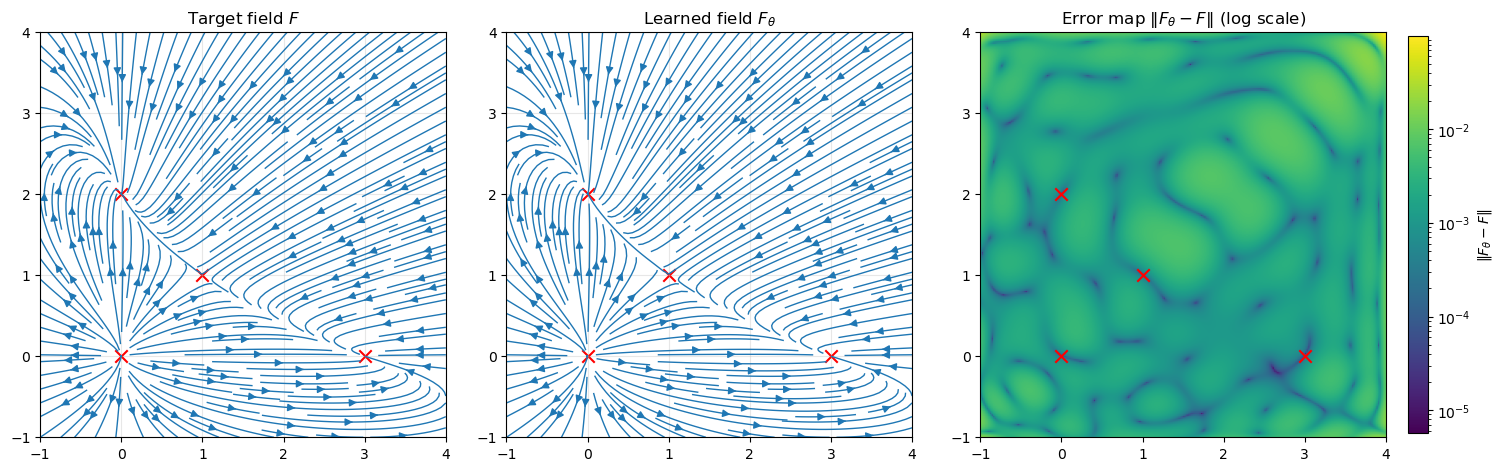

In [2]:
exp1.plot_vector_field(figures=None, close=False)
plt.show()

**Figs. 3-4.** Grid RMSE and fixed-point residual during training, for the QR-constrained model, the free MLP and
the MLP trained with the soft penalty ($\lambda = 1, 10, 50$); 5 seeds.

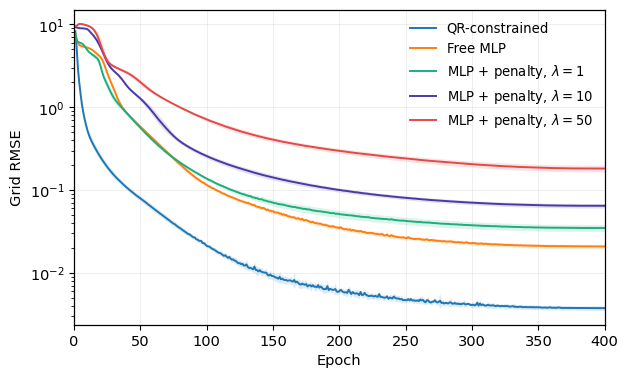

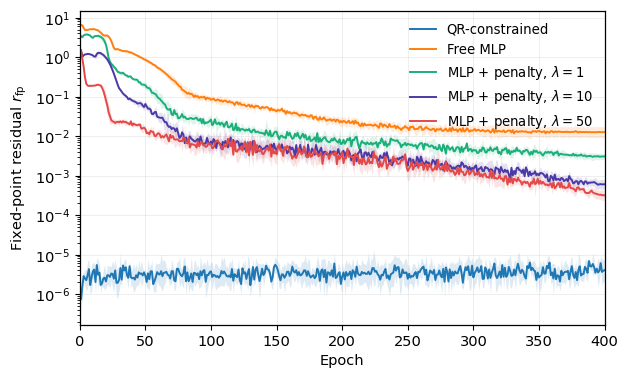

In [3]:
exp1.plot_training_curves(figures=None, close=False)
plt.show()

Numbers quoted in Section 5.2 for Experiment 1, the comparison during training and the check with a constant
learning rate (`experiments/paper_numbers.py`):

In [4]:
paper_numbers.exp1()
paper_numbers.training_comparison()
paper_numbers.robustness()

== Experiment 1 (QR, N=5e4, cosine, 5 seeds)
  grid_rmse              GM 3.752e-03 x/ 1.065   (arith 3.757e-03 +- 2.32e-04)
  max_error              GM 1.030e-01 x/ 1.065   (arith 1.031e-01 +- 6.72e-03)
  fixed_point_residual   GM 4.020e-06 x/ 1.837   (arith 4.591e-06 +- 2.39e-06)
  train minutes          arith 1.922 +- 0.038, GM 1.922e+00 x/ 1.020
== Comparison during training, N=5e4 cosine, last epoch (grid RMSE, r_fp)
  qr        grid 3.752e-03 x/ 1.065  r_fp GM 4.02e-06
  free_mlp  grid 2.084e-02 x/ 1.058  r_fp GM 1.26e-02
  pen_1     grid 3.483e-02 x/ 1.100  r_fp GM 3.05e-03
  pen_10    grid 6.456e-02 x/ 1.064  r_fp GM 6.01e-04
  pen_50    grid 1.818e-01 x/ 1.099  r_fp GM 3.17e-04
  qr        first epoch with GM grid RMSE <= 1e-1: 42
  free_mlp  first epoch with GM grid RMSE <= 1e-1: 108
  pen_1     first epoch with GM grid RMSE <= 1e-1: 120
  pen_10    first epoch with GM grid RMSE <= 1e-1: 201
  pen_50    first epoch with GM grid RMSE <= 1e-1: never
  QR GM below every baseline 

## Section 5.2, dependence on the dataset size

Every model is trained until the validation error stops improving, for $N_{\rm data}$ from 200 to
$5\times10^4$, 10 seeds; the penalty weight and the augmentation fraction are selected on validation.
Code: `experiments/exp1_dataset_size/`.

**Figs. 5-6.** Grid RMSE vs. dataset size, and trajectory error vs. time.

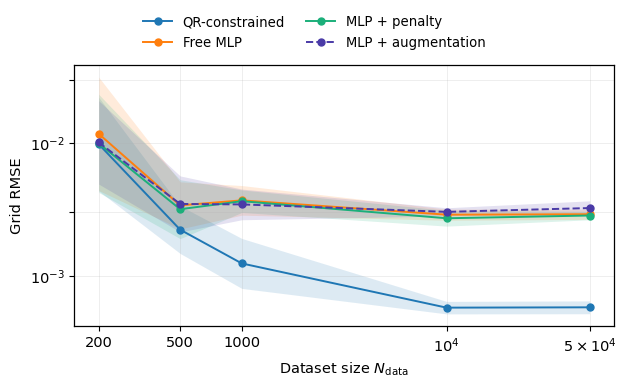

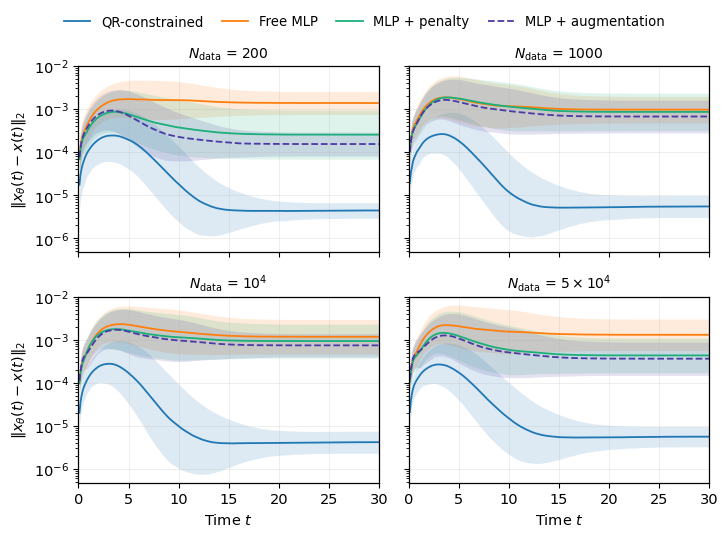

In [5]:
results, traj = ds.load()
ds.plot_grid_rmse(results, figures=None, close=False)
ds.plot_trajectory_error(traj, figures=None, close=False)
plt.show()

**Table 1.** Grid RMSE, local RMSE (within 0.25 of an equilibrium), fixed-point residual, Jacobian error at the
equilibria and trajectory error at $t = 30$.

In [6]:
names = {m: plotting.METHOD_STYLES[m][0] for m in ds.METHODS}
header = ["$N_{\\rm data}$", "Method", "Grid RMSE", "Local RMSE", "$r_{\\rm fp}$", "Jacobian error", "Traj. error ($t=30$)"]
rows = [[str(n) if i == 0 else "", names[m]] + [gm_gsd(ds.values(results, m, n, f)) for f in ds.TABLE_FIELDS]
        for n in ds.TABLE_N for i, m in enumerate(ds.METHODS)]
display(table(header, rows))

| $N_{\rm data}$ | Method | Grid RMSE | Local RMSE | $r_{\rm fp}$ | Jacobian error | Traj. error ($t=30$) |
|---|---|---|---|---|---|---|
| 200 | QR-constrained | 9.8e-03 &times;/&divide; 2.25 | 3.0e-04 &times;/&divide; 2.38 | 4.0e-06 &times;/&divide; 2.05 | 3.5e-03 &times;/&divide; 2.58 | 4.4e-06 &times;/&divide; 1.29 |
|  | Free MLP | 1.2e-02 &times;/&divide; 2.67 | 1.5e-03 &times;/&divide; 1.82 | 2.2e-03 &times;/&divide; 1.85 | 6.9e-03 &times;/&divide; 1.94 | 1.4e-03 &times;/&divide; 1.39 |
|  | MLP + penalty | 9.9e-03 &times;/&divide; 2.34 | 6.9e-04 &times;/&divide; 1.94 | 7.1e-04 &times;/&divide; 2.21 | 5.3e-03 &times;/&divide; 1.43 | 2.5e-04 &times;/&divide; 3.31 |
|  | MLP + augmentation | 1.0e-02 &times;/&divide; 2.06 | 6.2e-04 &times;/&divide; 1.25 | 2.8e-04 &times;/&divide; 1.58 | 6.3e-03 &times;/&divide; 1.41 | 1.5e-04 &times;/&divide; 1.66 |
| 1000 | QR-constrained | 1.2e-03 &times;/&divide; 1.54 | 2.4e-04 &times;/&divide; 1.24 | 4.8e-06 &times;/&divide; 1.91 | 2.9e-03 &times;/&divide; 1.36 | 5.4e-06 &times;/&divide; 1.57 |
|  | Free MLP | 3.7e-03 &times;/&divide; 1.29 | 1.3e-03 &times;/&divide; 1.28 | 1.7e-03 &times;/&divide; 1.35 | 6.8e-03 &times;/&divide; 1.31 | 9.6e-04 &times;/&divide; 1.63 |
|  | MLP + penalty | 3.6e-03 &times;/&divide; 1.22 | 1.1e-03 &times;/&divide; 1.38 | 1.4e-03 &times;/&divide; 1.57 | 6.2e-03 &times;/&divide; 1.19 | 8.5e-04 &times;/&divide; 1.83 |
|  | MLP + augmentation | 3.5e-03 &times;/&divide; 1.30 | 9.1e-04 &times;/&divide; 1.27 | 1.1e-03 &times;/&divide; 1.39 | 6.2e-03 &times;/&divide; 1.39 | 6.7e-04 &times;/&divide; 1.83 |
| 10000 | QR-constrained | 5.8e-04 &times;/&divide; 1.11 | 2.4e-04 &times;/&divide; 1.22 | 3.2e-06 &times;/&divide; 1.50 | 2.7e-03 &times;/&divide; 1.34 | 4.2e-06 &times;/&divide; 1.53 |
|  | Free MLP | 2.9e-03 &times;/&divide; 1.10 | 1.3e-03 &times;/&divide; 1.21 | 1.7e-03 &times;/&divide; 1.30 | 6.1e-03 &times;/&divide; 1.14 | 1.2e-03 &times;/&divide; 1.68 |
|  | MLP + penalty | 2.7e-03 &times;/&divide; 1.15 | 1.0e-03 &times;/&divide; 1.30 | 1.2e-03 &times;/&divide; 1.35 | 6.1e-03 &times;/&divide; 1.28 | 9.3e-04 &times;/&divide; 1.73 |
|  | MLP + augmentation | 3.0e-03 &times;/&divide; 1.07 | 9.6e-04 &times;/&divide; 1.19 | 1.1e-03 &times;/&divide; 1.31 | 6.8e-03 &times;/&divide; 1.21 | 7.4e-04 &times;/&divide; 1.42 |
| 50000 | QR-constrained | 5.8e-04 &times;/&divide; 1.12 | 2.4e-04 &times;/&divide; 1.14 | 4.1e-06 &times;/&divide; 1.61 | 2.8e-03 &times;/&divide; 1.31 | 5.6e-06 &times;/&divide; 1.62 |
|  | Free MLP | 2.9e-03 &times;/&divide; 1.09 | 1.3e-03 &times;/&divide; 1.30 | 1.7e-03 &times;/&divide; 1.41 | 6.3e-03 &times;/&divide; 1.09 | 1.3e-03 &times;/&divide; 1.55 |
|  | MLP + penalty | 2.8e-03 &times;/&divide; 1.08 | 7.9e-04 &times;/&divide; 1.16 | 7.4e-04 &times;/&divide; 1.28 | 6.5e-03 &times;/&divide; 1.17 | 4.3e-04 &times;/&divide; 1.95 |
|  | MLP + augmentation | 3.2e-03 &times;/&divide; 1.13 | 8.6e-04 &times;/&divide; 1.18 | 7.6e-04 &times;/&divide; 1.32 | 7.7e-03 &times;/&divide; 1.25 | 3.6e-04 &times;/&divide; 1.63 |

In [7]:
paper_numbers.dataset_size()

== Dataset size: GM per method and N
  grid_rmse
    N=   200 qr 9.81e-03  free 1.17e-02  pena 9.94e-03  aug_ 1.01e-02
    N=   500 qr 2.23e-03  free 3.39e-03  pena 3.18e-03  aug_ 3.48e-03
    N=  1000 qr 1.24e-03  free 3.70e-03  pena 3.65e-03  aug_ 3.45e-03
    N= 10000 qr 5.77e-04  free 2.89e-03  pena 2.71e-03  aug_ 3.03e-03
    N= 50000 qr 5.80e-04  free 2.91e-03  pena 2.85e-03  aug_ 3.24e-03
  local_rmse
    N=   200 qr 3.05e-04  free 1.52e-03  pena 6.87e-04  aug_ 6.15e-04
    N=   500 qr 1.58e-04  free 8.08e-04  pena 6.68e-04  aug_ 5.33e-04
    N=  1000 qr 2.44e-04  free 1.28e-03  pena 1.12e-03  aug_ 9.08e-04
    N= 10000 qr 2.42e-04  free 1.29e-03  pena 1.01e-03  aug_ 9.59e-04
    N= 50000 qr 2.41e-04  free 1.28e-03  pena 7.89e-04  aug_ 8.58e-04
  fixed_point_residual
    N=   200 qr 3.95e-06  free 2.24e-03  pena 7.05e-04  aug_ 2.78e-04
    N=   500 qr 3.92e-06  free 1.18e-03  pena 9.57e-04  aug_ 6.12e-04
    N=  1000 qr 4.81e-06  free 1.72e-03  pena 1.43e-03  aug_ 1.09e-03
    N

## Appendix B, limit cycle

Fig. 7 was produced by an earlier notebook version of `experiments/appB_limit_cycle/train_and_plot.py` without a
fixed seed; it is stored in `experiments/appB_limit_cycle/figures/` and can be reproduced, up to the random seed,
with `python reproduce.py train appB_limit_cycle` (about 20 minutes on a GPU).

## Appendix C, training on trajectories through the ODE solver

The models are trained on observed trajectories up to $T = 10$, by backpropagation through RK4, until the
validation error stops improving; 10 seeds. Code: `experiments/appC_trajectories/`.

**Fig. 8.** Trajectory error along the test trajectories (shaded: beyond the time range of the data).

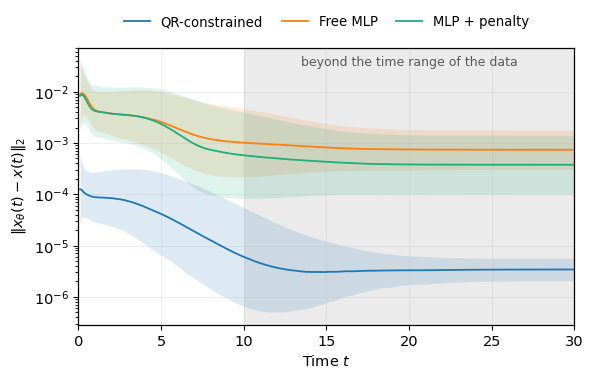

In [8]:
results_c, traj_c = appC.load()
appC.plot_trajectory_error(traj_c, figures=None, close=False)
plt.show()

**Table 2.** Trajectory errors within and beyond the time range of the data, fixed-point residual and Jacobian
error.

In [9]:
header = ["Method", "Traj. error, $0<t\\le10$", "Traj. error, $10<t\\le30$", "$r_{\\rm fp}$", "Jacobian error"]
rows = [[plotting.METHOD_STYLES[m][0]] + [gm_gsd([r[f] for r in results_c[m]]) for f in appC.TABLE_FIELDS]
        for m in appC.METHODS]
display(table(header, rows))

| Method | Traj. error, $0<t\le10$ | Traj. error, $10<t\le30$ | $r_{\rm fp}$ | Jacobian error |
|---|---|---|---|---|
| QR-constrained | 1.0e-04 &times;/&divide; 1.36 | 5.6e-06 &times;/&divide; 1.28 | 2.7e-06 &times;/&divide; 1.76 | 1.2e-01 &times;/&divide; 2.36 |
| Free MLP | 5.7e-03 &times;/&divide; 1.28 | 9.4e-04 &times;/&divide; 1.80 | 1.3e+00 &times;/&divide; 2.41 | 4.9e+00 &times;/&divide; 1.34 |
| MLP + penalty | 5.4e-03 &times;/&divide; 2.02 | 5.1e-04 &times;/&divide; 3.26 | 6.3e-04 &times;/&divide; 2.87 | 4.6e+00 &times;/&divide; 1.39 |

**Table 3.** Per equilibrium: fraction of the training observations within 0.25, residual
$\|F_\theta(\bar x^{(l)})\|_2$ (float64), Jacobian error (geometric means over the seeds) and number of seeds
with the correct stability type.

In [10]:
from experiments.systems import lotka_volterra as lv

short = {"qr": "QR", "free_mlp": "Free", "penalty_mlp": "Pen."}
header = ["Equilibrium", "Type", "Obs."] + [f"{q} {short[m]}" for q in ("residual", "Jacobian err.", "type ok")
                                            for m in appC.METHODS]
rows = []
for l, (name, kind) in enumerate(zip(lv.EQUILIBRIUM_NAMES, lv.EQUILIBRIUM_TYPES)):
    per = lambda m, f: [r["per_equilibrium"][l][f] for r in results_c[m]]
    obs = 100 * sum(per("qr", "obs_fraction_near")) / len(results_c["qr"])
    rows.append([name, kind, f"{obs:.2f}%"]
                + [f"{plotting.geo(per(m, f))[0]:.1e}" for f in ("residual_float64", "jac_err") for m in appC.METHODS]
                + [f"{sum(per(m, 'eig_signs_ok'))}/{len(results_c[m])}" for m in appC.METHODS])
display(table(header, rows))

| Equilibrium | Type | Obs. | residual QR | residual Free | residual Pen. | Jacobian err. QR | Jacobian err. Free | Jacobian err. Pen. | type ok QR | type ok Free | type ok Pen. |
|---|---|---|---|---|---|---|---|---|---|---|---|
| (0,0) | unstable node | 0.02% | 1.7e-06 | 1.3e+00 | 1.5e-04 | 1.1e-01 | 4.9e+00 | 4.4e+00 | 10/10 | 0/10 | 1/10 |
| (0,2) | stable node | 42.28% | 1.9e-06 | 8.9e-04 | 4.2e-04 | 2.7e-03 | 1.1e-01 | 8.9e-02 | 10/10 | 10/10 | 10/10 |
| (3,0) | stable node | 20.16% | 1.7e-06 | 1.4e-03 | 3.7e-04 | 1.2e-02 | 1.2e+00 | 1.0e+00 | 10/10 | 10/10 | 10/10 |
| (1,1) | saddle | 3.55% | 1.8e-06 | 3.6e-03 | 4.5e-04 | 8.6e-04 | 5.0e-02 | 1.0e-01 | 10/10 | 10/10 | 10/10 |

In [11]:
paper_numbers.trajectories()

== Training on trajectories (Appendix C); penalty lambda chosen on validation: 0.1 ({'0.01': 8.394564511433424e-06, '0.1': 5.804520729751856e-06, '1': 8.042586739716414e-06, '10': 0.00011579624835747779})
  QR-constrained   val 5.65e-09 | traj (0,10] 9.98e-05 (10,30] 5.58e-06 | t=30 3.41e-06 t=100 3.41e-06 | outcome acc 100.00% (min 100.0%) | r_fp 2.7e-06 | jac max 1.21e-01 | local 2.87e-03 | field: IC box 6.19e-02 whole box 4.98e-01 near data 1.89e-01 | stop: ['min_lr'], median steps 270500
  Free MLP         val 8.44e-06 | traj (0,10] 5.71e-03 (10,30] 9.39e-04 | t=30 7.37e-04 t=100 7.37e-04 | outcome acc 99.86% (min 99.6%) | r_fp 1.3e+00 | jac max 4.87e+00 | local 3.05e-01 | field: IC box 1.67e+00 whole box 3.40e+00 near data 1.75e+00 | stop: ['min_lr'], median steps 479500
  MLP + penalty    val 7.74e-06 | traj (0,10] 5.40e-03 (10,30] 5.11e-04 | t=30 3.76e-04 t=100 3.76e-04 | outcome acc 99.82% (min 99.2%) | r_fp 6.3e-04 | jac max 4.56e+00 | local 1.33e-01 | field: IC box 1.77e+00 w